In [ ]:
!pip install trl
!unip DPO.zip
from datasets import load_dataset
import pandas as pd
from transformers import AutoTokenizer, AutoModelForCausalLM
from trl import setup_chat_format, SFTConfig, SFTTrainer
from peft import LoraConfig, get_peft_model
import re

ds = load_dataset("openai/gsm8k", "socratic")
train_split = ds['train']
val_split = ds['test']

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 465.5/465.5 kB 14.4 MB/s eta 0:00:00
/bin/bash: line 1: unip: command not found


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

socratic/train-00000-of-00001.parquet:   0%|          | 0.00/2.68M [00:00<?, ?B/s]

socratic/test-00000-of-00001.parquet:   0%|          | 0.00/487k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/7473 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1319 [00:00<?, ? examples/s]

In [ ]:
#DPO TRAINING

# SAME BUT W LORA


from trl import DPOTrainer, DPOConfig
import os
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
import torch

# Disable wandb
os.environ["WANDB_DISABLED"] = "true"

model_name = "Qwen/Qwen3-0.6B"

# Load tokenizer once
tokenizer = AutoTokenizer.from_pretrained(model_name)
tokenizer.padding_side = 'left'  # Left padding for DPO
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

# Load base model for training
print("Loading model...")
model = AutoModelForCausalLM.from_pretrained(
    model_name,
    device_map="auto",
    torch_dtype=torch.float16
)

# Add LoRA
print("Adding LoRA adapters...")
lora_config = LoraConfig(
    r=16,
    lora_alpha=32,# target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    target_modules=["W_pack", "o_proj", "down_proj", "up_proj", "gate_proj"],
    lora_dropout=0.05,
    task_type="CAUSAL_LM"
)

# model = prepare_model_for_kbit_training(model)
model = get_peft_model(model, lora_config)
model.gradient_checkpointing_enable()

# Enable gradient checkpointing


# Load dataset
print("Loading preference dataset...")
# gsm8k_pref_dataset = load_dataset(
#     "json",
#     data_files="newlypulled.jsonl",
#     split="train"
# )



ref_model = AutoModelForCausalLM.from_pretrained(
    model_name,
    device_map="auto",
    torch_dtype=torch.float16
)


for p in ref_model.parameters():
    p.requires_grad = False
ref_model.eval()


gsm8k_pref_dataset = load_dataset("August4293/gsm8k_preference_dataset_it_1", split='train')


print(f"Dataset size: {len(gsm8k_pref_dataset)}")

# DPO Config - optimized for T4
args = DPOConfig(
    output_dir="./qwen3_dpo_cot",
    per_device_train_batch_size=1,  # Lower for T4
    gradient_accumulation_steps=8,  # Effective batch = 8
    learning_rate=5e-6,  # Higher than your 5e-6
    num_train_epochs=1,  # Less epochs for DPO
    warmup_ratio=0.1,
    beta=0.1,  # DPO beta parameter
    fp16=True,
    logging_steps=10,
    save_steps=50,
    save_total_limit=2,
    remove_unused_columns=False,
    report_to="none",
    gradient_checkpointing=True,
)




# Initialize trainer (no separate ref_model needed with LoRA)
print("Initializing DPO trainer...")
trainer = DPOTrainer(
    model=model,
    ref_model=ref_model,  # Uses LoRA adapter automatically
    train_dataset=gsm8k_pref_dataset,
    processing_class=tokenizer,
    args=args,
)

# Train
print("Starting training...")
trainer.train()

# Save final model
print("Saving model...")
trainer.save_model("./qwen3_dpo_final")
tokenizer.save_pretrained("./qwen3_dpo_final")

print("Done!")




tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json:   0%|          | 0.00/11.4M [00:00<?, ?B/s]

Loading model...


config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

... (14 outputs left out)

Starting training...


Step,Training Loss
10,0.676000
20,0.495400
30,0.326100
40,0.228700
50,0.192600
60,0.155100
70,0.103800
80,0.099500
90,0.099700


Using the `WANDB_DISABLED` environment variable is deprecated and will be removed in v5. Use the --report_to flag to control the integrations used for logging result (for instance --report_to none).
Using the `WANDB_DISABLED` environment variable is deprecated and will be removed in v5. Use the --report_to flag to control the integrations used for logging result (for instance --report_to none).


Saving model...
Done!


In [ ]:
!unzip SFT_qwen3_lora_out.zip

Archive:  SFT_qwen3_lora_out.zip
   creating: qwen3_lora_out/
  inflating: qwen3_lora_out/merges.txt  
  inflating: qwen3_lora_out/chat_template.jinja  
  inflating: qwen3_lora_out/README.md  
  inflating: qwen3_lora_out/training_args.bin  
  inflating: qwen3_lora_out/adapter_config.json  
   creating: qwen3_lora_out/checkpoint-2500/
  inflating: qwen3_lora_out/checkpoint-2500/merges.txt  
  inflating: qwen3_lora_out/checkpoint-2500/chat_template.jinja  
  inflating: qwen3_lora_out/checkpoint-2500/README.md  
  inflating: qwen3_lora_out/checkpoint-2500/rng_state.pth  
  inflating: qwen3_lora_out/checkpoint-2500/trainer_state.json  
  inflating: qwen3_lora_out/checkpoint-2500/training_args.bin  
  inflating: qwen3_lora_out/checkpoint-2500/adapter_config.json  
  inflating: qwen3_lora_out/checkpoint-2500/scaler.pt  
  inflating: qwen3_lora_out/checkpoint-2500/vocab.json  
  inflating: qwen3_lora_out/checkpoint-2500/special_tokens_map.json  
  inflating: qwen3_lora_out/checkpoint-2500/opt

In [ ]:
#SFT

import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

device = "cuda" if torch.cuda.is_available() else "cpu"
model_name_or_path = "./qwen3_lora_out"

tokenizer = AutoTokenizer.from_pretrained(model_name_or_path)
model = AutoModelForCausalLM.from_pretrained(model_name_or_path)
model.to(device)

# Prompt: plain CoT style, simple and clean
prompt = (
    "Solve the following math problem step by step:\n"
    # "Problem: Natalia sold 48 clips in April and half as many in May. How many clips did she sell in total?"
    # "Problem: Dat has 120 kg of bananas, he won the lottery doubled them, how many kg of bananas does he have"
    "Problem: Huan's got 10 apples, he bought 15 more. How many apples he having?"

)

inputs = tokenizer(prompt, return_tensors="pt").to(device)

outputs = model.generate(
    **inputs,
    max_new_tokens=150,
    temperature=0.7,
    do_sample=False,  # deterministic output
    eos_token_id=tokenizer.eos_token_id
)

answer = tokenizer.decode(outputs[0], skip_special_tokens=True)
print(answer)




The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Solve the following math problem step by step:
Problem: Huan's got 10 apples, he bought 15 more. How many apples he having? ** Huan has 10+15 = 25 apples

Final answer: 25


In [ ]:
#DPO

import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

device = "cuda" if torch.cuda.is_available() else "cpu"
model_name_path = "./qwen3_dpo_final"

dpo_tokenizer = AutoTokenizer.from_pretrained(model_name_path)
dpo_model = AutoModelForCausalLM.from_pretrained(model_name_path)
dpo_model.to(device)

# Prompt: plain CoT style, simple and clean
prompt = (
    "Solve the following math problem step by step, just give the answer when you reach Final Answer :\n"
    # "Problem: Natalia sold 48 clips in April and half as many in May. How many clips did she sell in total?"
    "Problem: Huan's got 10 apples, he bought 15 more. How many apples he having?"

)

inputs = dpo_tokenizer(prompt, return_tensors="pt").to(device)


from transformers import StoppingCriteria, StoppingCriteriaList
class StopAfterFinalAnswer(StoppingCriteria):
    def __init__(self, tokenizer, stop_strs, extra_tokens=5):
        self.stop_ids_list = [tokenizer(s, add_special_tokens=False).input_ids for s in stop_strs]
        self.extra_tokens = extra_tokens
        self.past_stop = False
        self.counter = 0

    def __call__(self, input_ids, scores, **kwargs):
        if not self.past_stop:
            for stop_ids in self.stop_ids_list:
                if input_ids[0][-len(stop_ids):].tolist() == stop_ids:
                    self.past_stop = True
                    return False  # allow extra tokens
        else:
            self.counter += 1
            if self.counter >= self.extra_tokens:
                return True
        return False

stop_sequences = ["Final Answer", "Final answer:", "### Final Answer", "**Final Answer**"]
stop_criteria = StoppingCriteriaList([StopAfterFinalAnswer(dpo_tokenizer, stop_sequences, extra_tokens=8)])


outputs = dpo_model.generate(
    **inputs,
    max_new_tokens=1500,
    temperature=0.7,
    do_sample=False,  # deterministic output
    eos_token_id=dpo_tokenizer.eos_token_id,
    repetition_penalty=1.2,
    stopping_criteria=stop_criteria
)

answer = dpo_tokenizer.decode(outputs[0], skip_special_tokens=True)
print(answer)


Solve the following math problem step by step, just give the answer when you reach Final Answer :
Problem: Huan's got 10 apples, he bought 15 more. How many apples he having? 

Step-by-step Explanation:

Okay, let me try to figure out this problem. So, Huan has 10 apples initially. Then he buys 15 more. The question is asking how many apples he currently has.

Hmm, right. Let me break it down. First, we start with 10 apples. Then, he adds another 15. To find the total number of apples after adding, I think we need to add those two numbers together. That makes sense because each time he buys more apples, that's an addition operation.

So, starting with 10 plus 15 equals... wait, what does 10 + 15 equal? Well, 10 plus 15 can be broken into (10 + 10) + 5 which is 20 + 5 = 25. Alternatively, maybe I should do it directly as 10 + 15. Either way, both methods lead to 25. Therefore, after buying the additional 15 apples, Huan will have 25 apples in total.

Let me double-check my reasoning. In

In [ ]:
from collections import Counter
from fractions import Fraction
import re

def tokenize(text):
    return text.strip().split()

def f1_score(reference, prediction):
    """Token-level F1"""
    ref_tokens = tokenize(reference)
    pred_tokens = tokenize(prediction)

    common = Counter(ref_tokens) & Counter(pred_tokens)
    num_same = sum(common.values())

    if num_same == 0:
        return 0.0

    precision = num_same / len(pred_tokens)
    recall = num_same / len(ref_tokens)
    f1 = 2 * (precision * recall) / (precision + recall)
    return f1

def numeric_equal(ref, pred):
    # Try to find 'Final answer' first
    for text in [pred, ref]:
        m = re.findall(r'[-+]?\d+\.?\d*', text)
        if m:
            # pick the last number
            return float(m[-1]) == float(re.findall(r'[-+]?\d+\.?\d*', ref)[-1])
    return False

def evaluate(outputs, references):
    f1s = []
    numeric_correct = []
    for pred, ref in zip(outputs, references):
        f1s.append(f1_score(ref, pred))
        numeric_correct.append(int(numeric_equal(ref, pred)))
    return f1s, numeric_correct



gsm8k_test_dataset = load_dataset("August4293/gsm8k_preference_dataset_it_1", split='test')
eval_prompts = [ex['prompt'] for ex in gsm8k_test_dataset][:10]
references = [ex['chosen'] for ex in gsm8k_test_dataset][:10]

sft_outputs = []
for prompt in eval_prompts:  # list of strings from your dataset
    inputs = tokenizer(prompt, return_tensors="pt").to(device)
    output_ids = model.generate(**inputs, max_new_tokens=150)
    pred_text = tokenizer.decode(output_ids[0], skip_special_tokens=True)
    sft_outputs.append(pred_text)

dpo_outputs = []
for prompt in eval_prompts:
    inputs = dpo_tokenizer(prompt, return_tensors="pt").to(device)
    output_ids = dpo_model.generate(**inputs, max_new_tokens=1500, stopping_criteria=stop_criteria, repetition_penalty=1.2)
    pred_text = dpo_tokenizer.decode(output_ids[0], skip_special_tokens=True)
    dpo_outputs.append(pred_text)

sft_f1, sft_numeric = evaluate(sft_outputs, references)
dpo_f1, dpo_numeric = evaluate(dpo_outputs, references)

In [ ]:
def average(lst):
    return sum(lst)/len(lst)

print("SFT avg F1:", average(sft_f1))
print("SFT avg numeric correctness:", average(sft_numeric))
print("DPO avg F1:", average(dpo_f1))
print("DPO avg numeric correctness:", average(dpo_numeric))

for i in range(len(eval_prompts)):
    print(f"Prompt {i+1}: {eval_prompts[i]}")
    # print("Reference:", references[i])
    print("SFT output:", sft_outputs[i])
    print("DPO output:", dpo_outputs[i])
    print("---")

SFT avg F1: 0.354922010889015
SFT avg numeric correctness: 0.4
DPO avg F1: 0.2801389949723147
DPO avg numeric correctness: 0.2
Prompt 1: Antoine owns a strawberry farm that supplies strawberries to his local bakeries. The first bakery needs 2 sacks, the second bakery needs 4 sacks, and the third bakery needs 12 sacks of strawberries per week. How many sacks of strawberries does he need to supply all the bakeries in 4 weeks?
SFT output: Antoine owns a strawberry farm that supplies strawberries to his local bakeries. The first bakery needs 2 sacks, the second bakery needs 4 sacks, and the third bakery needs 12 sacks of strawberries per week. How many sacks of strawberries does he need to supply all the bakeries in 4 weeks? ** How many sacks of strawberries does Antoine need to supply all the bakeries in 4 weeks? ** How many sacks of strawberries does Antoine need to supply all the bakeries in 4 weeks? ** How many sacks of strawberries does Antoine need to supply all the bakeries in 4 wee

In [ ]:
from datasets import load_dataset
import torch
import re

def calc_score_fast(model, tokenizer, num_samples=50, batch_size=8):
    dataset = load_dataset("gsm8k", "main", split="test").select(range(num_samples))
    device = next(model.parameters()).device
    correct = 0

    for i in range(0, num_samples, batch_size):
        batch = dataset[i:i+batch_size]
        prompts = [f"Q: {q}\nA:" for q in batch['question']]
        true_ans = [float(re.search(r'####\s*(-?\d+)', a).group(1)) for a in batch['answer']]

        inputs = tokenizer(prompts, return_tensors="pt", padding=True).to(device)
        with torch.no_grad():
            outputs = model.generate(**inputs, max_new_tokens=256, pad_token_id=tokenizer.eos_token_id)

        for j, output in enumerate(outputs):
            response = tokenizer.decode(output, skip_special_tokens=True)
            nums = re.findall(r'-?\d+', response.split("A:")[-1])
            pred = float(nums[-1]) if nums else None
            if pred == true_ans[j]:
                correct += 1

    return (correct / num_samples) * 100



# === METRIC ĐÁNH GIÁ 3 MÔ HÌNH: BASE / SFT / DPO ===
import torch
import pandas as pd
from transformers import AutoTokenizer, AutoModelForCausalLM

device = "cuda" if torch.cuda.is_available() else "cpu"

base_model_name = "Qwen/Qwen3-0.6B"

results = []

# 1) Base pre-trained model
base_tokenizer = AutoTokenizer.from_pretrained(base_model_name)
base_model = AutoModelForCausalLM.from_pretrained(base_model_name).to(device)
base_acc = calc_score_fast(base_model, base_tokenizer, num_samples=200, batch_size=8)
results.append({"model": "Base", "accuracy": base_acc})


sft_acc = calc_score_fast(model, tokenizer, num_samples=200, batch_size=8)
results.append({"model": "SFT", "accuracy": sft_acc})

dpo_acc = calc_score_fast(dpo_model, dpo_tokenizer, num_samples=200, batch_size=8)
results.append({"model": "DPO", "accuracy": dpo_acc})

df = pd.DataFrame(results)
df

README.md: 0.00B [00:00, ?B/s]

main/train-00000-of-00001.parquet:   0%|          | 0.00/2.31M [00:00<?, ?B/s]

main/test-00000-of-00001.parquet:   0%|          | 0.00/419k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/7473 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1319 [00:00<?, ? examples/s]

A decoder-only architecture is being used, but right-padding was detected! For correct generation results, please set `padding_side='left'` when initializing the tokenizer.
A decoder-only architecture is being used, but right-padding was detected! For correct generation results, please set `padding_side='left'` when initializing the tokenizer.
A decoder-only architecture is being used, but right-padding was detected! For correct generation results, please set `padding_side='left'` when initializing the tokenizer.
A decoder-only architecture is being used, but right-padding was detected! For correct generation results, please set `padding_side='left'` when initializing the tokenizer.
A decoder-only architecture is being used, but right-padding was detected! For correct generation results, please set `padding_side='left'` when initializing the tokenizer.
A decoder-only architecture is being used, but right-padding was detected! For correct generation results, please set `padding_side='le

,model,accuracy
0,Base,9.0
1,SFT,43.5
2,DPO,13.0


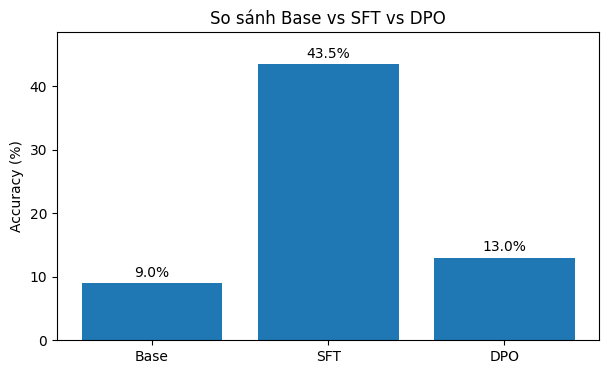

In [ ]:
# === VẼ BIỂU ĐỒ SO SÁNH ACCURACY 3 MÔ HÌNH ===
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.bar(df["model"], df["accuracy"])
plt.ylabel("Accuracy (%)")
plt.title("So sánh Base vs SFT vs DPO")

for i, v in enumerate(df["accuracy"]):
    plt.text(i, v + 1, f"{v:.1f}%", ha="center")

plt.ylim(0, max(df["accuracy"]) + 5)
plt.show()